Parameters:
  m     = 0.0266667
  k     = 48090
  xi    = 1603
  x0    = 0.01
  alpha = 1.75e-08
  C     = 0-87.4574j

Roots (omega) in rad/s:
  root 0: -1899.14+1.92047j   |residual|=2.426e-09
  root 1: 1899.14+1.92047j   |residual|=3.290e-09
  root 2: 5.65059e-21-0.0909309j   |residual|=1.421e-14


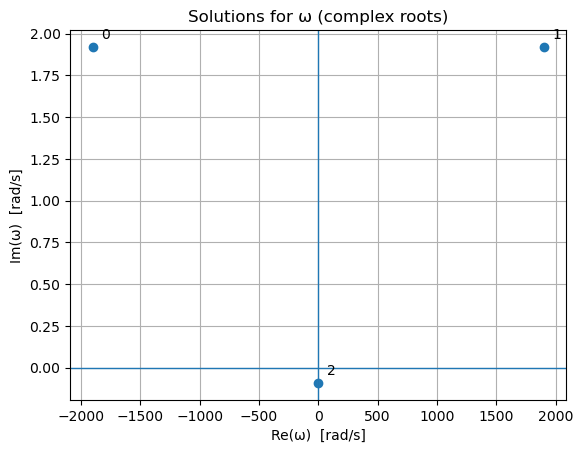

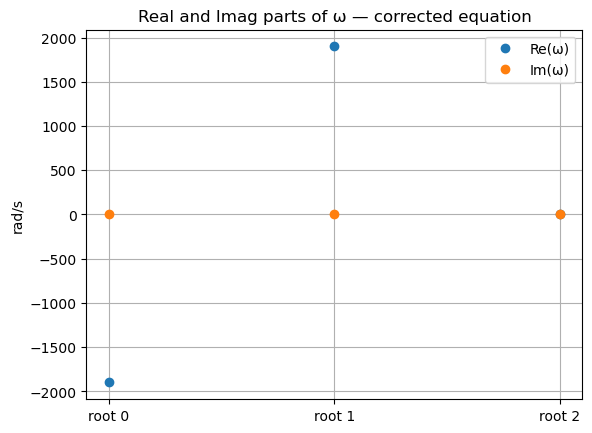

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Given / user-specified params
# ----------------------------
AR = 0.02      # m^2
AD = 0.002     # m^2
L  = 1.0       # m
rho = 4.0      # kg/m^3

P0 = 572500.0
gamma = 1.4

beta = 0.1     # damping coefficient (as used in your equation)
x0 = 0.01      # m

# NEW parameter in corrected equation:
alpha = 1.75e-8    # <-- set this to your alpha (units per your model)

# ----------------------------
# Derived parameters
# ----------------------------
m = (1.0 / 3.0) * rho * AR * L

# k = P0*gamma*AR^2 / V0, with V0 = L*AR/3
V0 = L * AR / 3.0
k = P0 * gamma * AR**2 / V0

# xi = P0*gamma*AD/L
xi = P0 * gamma * AD / L

# ----------------------------
# Corrected equation (from screenshot):
#   -m ω^2 x0 + (β i) ω x0 + 2 k x0  ==  ξ * [ i P0 (1 - (AR L)^γ (AR (L-3x0))^-γ) α ] / (AD ρ ω)
#
# Let geom = 1 - (AR L)^γ (AR (L-3x0))^-γ = 1 - (L/(L-3x0))^γ
#
# Multiply both sides by ω:
#   x0(-m ω^2 + iβ ω + 2k) ω - C = 0
# => -m x0 ω^3 + iβ x0 ω^2 + 2k x0 ω - C = 0
#
# where C = ξ * i P0 * geom * α / (AD ρ)
# ----------------------------
geom_factor = 1.0 - (L / (L - 3.0 * x0))**gamma
C = (1j * xi * P0 * geom_factor * alpha) / (AD * rho)

# Cubic coefficients for: a3 ω^3 + a2 ω^2 + a1 ω + a0 = 0
coeffs = [-m * x0, 1j * beta * x0, 2.0 * k * x0, -C]

roots = np.roots(coeffs)

# ----------------------------
# Print solutions + residual check
# ----------------------------
def poly_val(w, c):
    # Evaluate c[0]*w^3 + c[1]*w^2 + c[2]*w + c[3]
    return ((c[0]*w + c[1])*w + c[2])*w + c[3]

print("Parameters:")
print(f"  m     = {m:.6g}")
print(f"  k     = {k:.6g}")
print(f"  xi    = {xi:.6g}")
print(f"  x0    = {x0:.6g}")
print(f"  alpha = {alpha:.6g}")
print(f"  C     = {C:.6g}")

print("\nRoots (omega) in rad/s:")
for i, r in enumerate(roots):
    resid = poly_val(r, coeffs)
    print(f"  root {i}: {r:.6g}   |residual|={abs(resid):.3e}")

# ----------------------------
# Plot roots in complex plane
# ----------------------------
plt.figure()
plt.axhline(0, linewidth=1)
plt.axvline(0, linewidth=1)
plt.scatter(roots.real, roots.imag)

for i, r in enumerate(roots):
    plt.annotate(f"{i}", (r.real, r.imag), textcoords="offset points", xytext=(6, 6))

plt.xlabel("Re(ω)  [rad/s]")
plt.ylabel("Im(ω)  [rad/s]")
plt.title("Solutions for ω (complex roots)")
plt.grid(True)

# ----------------------------
# Plot Re/Im parts side-by-side
# ----------------------------
plt.figure()
idx = np.arange(len(roots))
plt.plot(idx, roots.real, "o", label="Re(ω)")
plt.plot(idx, roots.imag, "o", label="Im(ω)")
plt.xticks(idx, [f"root {i}" for i in idx])
plt.ylabel("rad/s")
plt.title("Real and Imag parts of ω — corrected equation")
plt.grid(True)
plt.legend()

plt.show()


In [3]:
print(2*np.pi*np.sqrt(2*k/m)/(2*100))

59.66338548358536


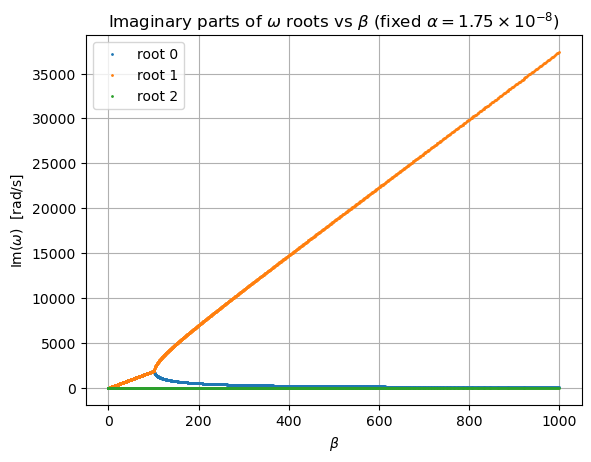

In [4]:
# ============================================================
# APPEND: sweep beta and plot Im(omega roots) vs beta (alpha fixed)
# ============================================================
import itertools

alpha_fixed = 1.75e-8

def roots_for_beta(beta_val: float) -> np.ndarray:
    # Recompute constant term with fixed alpha
    C_local = (1j * xi * P0 * geom_factor * alpha_fixed) / (AD * rho)
    coeffs_local = [-m * x0, 1j * beta_val * x0, 2.0 * k * x0, -C_local]
    return np.roots(coeffs_local)

def best_match(prev: np.ndarray, curr: np.ndarray) -> np.ndarray:
    """Match current roots to previous roots by minimal total distance (3! brute force)."""
    best = None
    best_cost = np.inf
    for perm in itertools.permutations(range(3)):
        cand = curr[list(perm)]
        cost = np.sum(np.abs(cand - prev))
        if cost < best_cost:
            best_cost = cost
            best = cand
    return best

betas = np.logspace(np.log10(1000), np.log10(0.1), 4000)

roots_tracked = np.zeros((3, betas.size), dtype=complex)

# init: label roots by real part at first beta
r0 = roots_for_beta(betas[0])
r0 = r0[np.argsort(r0.real)]
roots_tracked[:, 0] = r0

prev = r0
for i in range(1, betas.size):
    r = roots_for_beta(betas[i])
    r = best_match(prev, r)
    roots_tracked[:, i] = r
    prev = r

plt.figure()
for j in range(3):
    plt.plot(betas, roots_tracked[j, :].imag, ".", markersize=2, label=f"root {j}")


# plt.plot(betas, roots_tracked[2, :].imag, ".", markersize=2, label=f"root {0}")

#plt.xscale("log")
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\mathrm{Im}(\omega)$  [rad/s]")
plt.title(r"Imaginary parts of $\omega$ roots vs $\beta$ (fixed $\alpha=1.75\times 10^{-8}$)")
plt.grid(True, which="both")
plt.legend()
plt.show()


array([-1.53010696e+03+1.12504546e+03j,  1.53010696e+03+1.12504546e+03j,
        3.24849223e-18-9.09257713e-02j])

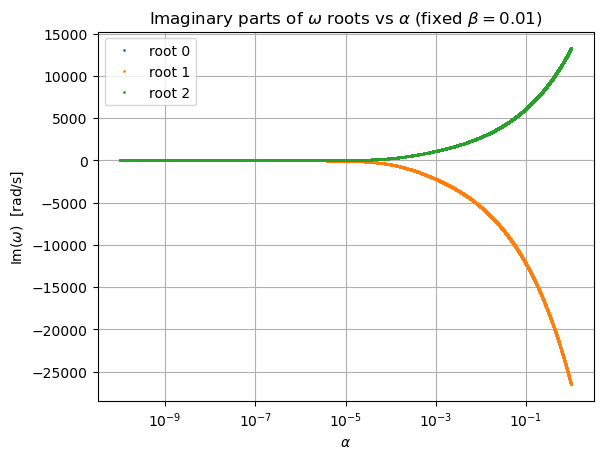

In [65]:
# ============================================================
# APPEND: sweep alpha and plot Im(omega roots) vs alpha (beta fixed)
# ============================================================
beta_fixed = 0.1

def roots_for_alpha(alpha_val: float) -> np.ndarray:
    C_local = (1j * xi * P0 * geom_factor * alpha_val) / (AD * rho)
    coeffs_local = [-m * x0, 1j * beta_fixed * x0, 2.0 * k * x0, -C_local]
    return np.roots(coeffs_local)

# alpha sweep over decades (1e-9 -> 1e-7)
alphas = np.logspace(np.log10(1e-10), np.log10(1), 20000)

roots_tracked_a = np.zeros((3, alphas.size), dtype=complex)

# init label by real part at first alpha
r0a = roots_for_alpha(alphas[0])
r0a = r0a[np.argsort(r0a.real)]
roots_tracked_a[:, 0] = r0a

prev = r0a
for i in range(1, alphas.size):
    r = roots_for_alpha(alphas[i])
    r = best_match(prev, r)   # reuse best_match from above block
    roots_tracked_a[:, i] = r
    prev = r

plt.figure()
for j in range(3):
    plt.plot(alphas, roots_tracked_a[j, :].imag, ".", markersize=2, label=f"root {j}")
plt.xscale("log")
plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\mathrm{Im}(\omega)$  [rad/s]")
plt.title(r"Imaginary parts of $\omega$ roots vs $\alpha$ (fixed $\beta=0.01$)")
plt.grid(True, which="both")
plt.legend()
plt.show()


In [111]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Given data (yours)
# -----------------------------
gamma = 1.41
R = 287
cp = 1050
cv = 744
m = 0.0015  # kg

L  = 0.5       # m

P_in, P_out = 6e5, 5.45e5
P0 = (P_in + P_out) / 2 * 1.00

T_in = 300
T0 = T_in

A_neck =2.85e-4
L_neck = 0.15
m_gas  = 0.0015
V0_cv  = 3.93e-4
V0_pass = 3.93e-4

# f = 135.0
# omega = 2*np.pi*f
# Q = 60.0
# b_gas = omega * m_gas / Q  # (not used below)

zeta = 0.6
dP = P_in - P_out
dP_max = dP / (2*zeta)
m_max = 0.001

# -----------------------------
# Unknowns to FILL IN
# -----------------------------
alpha1 = 2.258589e-08  # number, from fit
alpha2 = -3.582265e-26  # number, from fit
AD     = 0.85e-4  # 
rho    = 1.276  # kg/m^3
xi = P0* AD*A_neck*gamma/(V0_cv) ## go for even distribution of CV, mass, Passive later
# -----------------------------
# Model pieces
# -----------------------------
def k_effective(P0_val=P0):
    # Small-signal gas-spring; choose effective volume as needed
    V_eff = V0_cv ## go for even distribution of CV, mass, Passive later
    return gamma * P0_val * (A_neck**2) / V_eff # from notes

omega = np.sqrt(2*k_effective()/m)
beta = 0.005  # add linear damping here if you have it
Q = omega * m_gas / beta
print("The Q Value Is", Q)

def beta_prime(omega_val, x):
    """
    β′ = β + (xi/ω^2) * [ 3 P0 α1 γ / (AD * L_neck * ρ)
                         − (243 * 5 * (P0^5 α2^5 γ^5) x^4) / (AD * L_neck^5 * ρ) ]
    """
    C1 = (3.0 * P0 * alpha1 * gamma) / (AD * L_neck * rho)
    C2 = (243.0 * 5.0 * (P0**5 * (alpha2) * (gamma**5))) / (AD * (L_neck**5) * rho)
    return (beta - (C1 + C2 * x**4) / (omega_val**2)) * xi

def lambdas(beta_p, m, k):
    # λ = (-β′ ± sqrt(β′^2 - 8 m k)) / (2 m)  (use your exact characteristic)
    disc = beta_p**2 - 8.0*m*k
    sqrt_disc = np.sqrt(disc + 0j)
    lam1 = (-beta_p + sqrt_disc) / (2.0*m)
    lam2 = (-beta_p - sqrt_disc) / (2.0*m)
    return lam1, lam2

# -----------------------------
# Sweep vs x and plot
# -----------------------------
x_grid = np.linspace(-0.01*L_neck, 0.01*L_neck, 400)
k = k_effective(P0)
m = m_gas

beta_p = beta_prime(omega, x_grid)
lam1, lam2 = lambdas(beta_p, m, k)



The Q Value Is 141.49350658097407


In [112]:
sign_changes = np.where(np.diff(np.sign(beta_p)))[0]

# Interpolate to find more precise zero crossing locations
sign_changes_beta = np.where(np.diff(np.sign(beta_p)))[0]
zero_crossings_beta = []
for idx in sign_changes_beta:
    x0, x1 = x_grid[idx], x_grid[idx + 1]
    y0, y1 = beta_p[idx], beta_p[idx + 1]
    x_zero = x0 - y0 * (x1 - x0) / (y1 - y0)
    zero_crossings_beta.append(x_zero)

# Find branching/merging points: where Im(λ₁) transitions from/to zero
# Use a small threshold to detect near-zero values
imag_lam1 = np.imag(lam1)
threshold = 0.01 * np.max(np.abs(imag_lam1))  # 1% of max as threshold
is_nonzero = np.abs(imag_lam1) > threshold

# Find transitions (False->True = branching, True->False = merging)
transitions = np.where(np.diff(is_nonzero.astype(int)))[0]
branch_merge_points = []
for idx in transitions:
    # Interpolate to find where |Im(λ₁)| crosses threshold
    x0, x1 = x_grid[idx], x_grid[idx + 1]
    y0, y1 = np.abs(imag_lam1[idx]), np.abs(imag_lam1[idx + 1])
    x_trans = x0 + (threshold - y0) * (x1 - x0) / (y1 - y0)
    branch_merge_points.append(x_trans)

print(f"Beta prime zero crossings at x = {zero_crossings_beta}")
print(f"Branch/merge points at x = {branch_merge_points}")

Beta prime zero crossings at x = [np.float64(-0.0010556833220536008), np.float64(0.0010556833220536008)]
Branch/merge points at x = [np.float64(-0.001477054747931907), np.float64(0.0014770547479319065)]


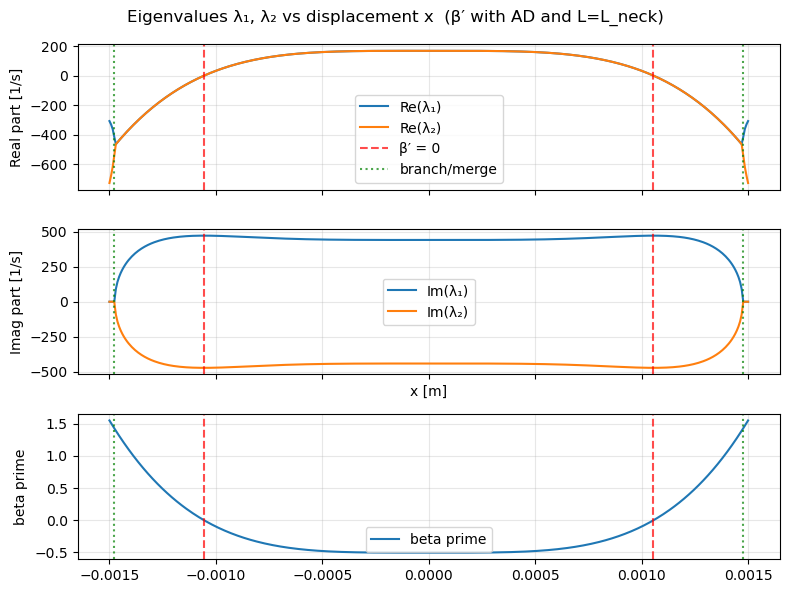

In [115]:
fig, axs = plt.subplots(3, 1, figsize=(8, 6), sharex=True)

axs[0].plot(x_grid, np.real(lam1), label="Re(λ₁)")
axs[0].plot(x_grid, np.real(lam2), label="Re(λ₂)")
axs[0].set_ylabel("Real part [1/s]"); axs[0].grid(alpha=0.3); axs[0].legend()

axs[1].plot(x_grid, np.imag(lam1), label="Im(λ₁)")
axs[1].plot(x_grid, np.imag(lam2), label="Im(λ₂)")
axs[1].set_xlabel("x [m]"); axs[1].set_ylabel("Imag part [1/s]")
axs[1].grid(alpha=0.3); axs[1].legend()

axs[2].plot(x_grid, beta_p, label="beta prime")
axs[2].set_ylabel("beta prime"); axs[2].grid(alpha=0.3); axs[2].legend()

# Add vertical lines at beta prime zero crossings (red)
for i, x_zero in enumerate(zero_crossings_beta):
    for ax in axs:
        ax.axvline(x=x_zero, color='red', linestyle='--', alpha=0.7, linewidth=1.5,
                   label="β′ = 0" if (ax == axs[0] and i == 0) else "")

# Add vertical lines at branch/merge points (green)
for i, x_bm in enumerate(branch_merge_points):
    for ax in axs:
        ax.axvline(x=x_bm, color='green', linestyle=':', alpha=0.7, linewidth=1.5,
                   label="branch/merge" if (ax == axs[0] and i == 0) else "")

# Update legend for first subplot to include vertical lines
axs[0].legend()

plt.suptitle("Eigenvalues λ₁, λ₂ vs displacement x  (β′ with AD and L=L_neck)")
plt.tight_layout(); plt.show()

In [116]:
P_stable_high = (A_neck*L)**gamma*P0*(A_neck*(L+3*zero_crossings_beta[0]))**(-gamma)

P_stable_low = (A_neck*L)**gamma*P0*(A_neck*(L-3*zero_crossings_beta[0]))**(-gamma)
print(P_stable_high)
print(P_stable_low)

577652.3525389971
567425.702923999


In [82]:
def stable_pressures_for_A_neck(A_neck_val):
    xi_local = P0 * AD * A_neck_val * gamma / V0_cv
    k_local = gamma * P0 * (A_neck_val**2) / (V0_pass + V0_cv)
    omega_local = np.sqrt(2 * k_local / m)
    x_grid_local = np.linspace(-0.01 * L_neck, 0.01 * L_neck, 400)

    C1 = (3.0 * P0 * alpha1 * gamma) / (AD * L_neck * rho)
    C2 = (243.0 * 5.0 * (P0**5 * alpha2 * gamma**5)) / (AD * L_neck**5 * rho)
    beta_p_local = (beta - (C1 + C2 * x_grid_local**4) / omega_local**2) * xi_local

    sign_changes_local = np.where(np.diff(np.sign(beta_p_local)))[0]
    if len(sign_changes_local) == 0:
        return np.nan, np.nan

    idx = sign_changes_local[0]
    x0, x1 = x_grid_local[idx], x_grid_local[idx + 1]
    y0, y1 = beta_p_local[idx], beta_p_local[idx + 1]
    x_zero = x0 - y0 * (x1 - x0) / (y1 - y0)

    P_high = (A_neck_val * L)**gamma * P0 * (A_neck_val * (L + 3 * x_zero))**(-gamma)
    P_low = (A_neck_val * L)**gamma * P0 * (A_neck_val * (L - 3 * x_zero))**(-gamma)
    return P_high, P_low

A_neck_grid = np.linspace(0.5 * A_neck, 1.5 * A_neck, 300)
P_stable_high_grid = np.empty_like(A_neck_grid)
P_stable_low_grid = np.empty_like(A_neck_grid)

for i, A_neck_val in enumerate(A_neck_grid):
    P_stable_high_grid[i], P_stable_low_grid[i] = stable_pressures_for_A_neck(A_neck_val)


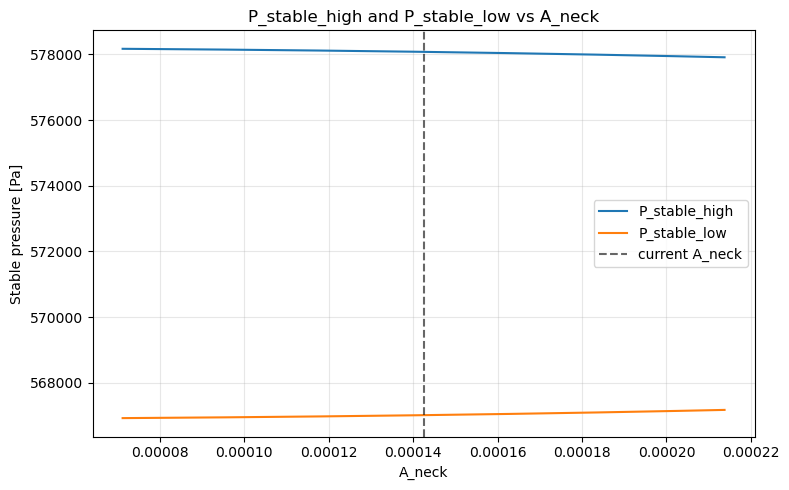

In [46]:
plt.figure(figsize=(8, 5))
plt.plot(A_neck_grid, P_stable_high_grid, label="P_stable_high")
plt.plot(A_neck_grid, P_stable_low_grid, label="P_stable_low")
plt.axvline(A_neck, color='k', linestyle='--', alpha=0.6, label="current A_neck")
plt.xlabel("A_neck")
plt.ylabel("Stable pressure [Pa]")
plt.title("P_stable_high and P_stable_low vs A_neck")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [71]:
def stable_pressures_for_volumes(V0_cv_val, V0_pass_val):
    xi_local = P0 * AD * A_neck * gamma / V0_cv_val
    k_local = gamma * P0 * (A_neck**2) / ((V0_pass_val + V0_cv_val)/2)
    omega_local = np.sqrt(2 * k_local / m)
    x_grid_local = np.linspace(-0.01 * L_neck, 0.01 * L_neck, 400)

    C1 = (3.0 * P0 * alpha1 * gamma) / (AD * L_neck * rho)
    C2 = (243.0 * 5.0 * (P0**5 * alpha2 * gamma**5)) / (AD * L_neck**5 * rho)
    beta_p_local = (beta - (C1 + C2 * x_grid_local**4) / omega_local**2) * xi_local

    sign_changes_local = np.where(np.diff(np.sign(beta_p_local)))[0]
    if len(sign_changes_local) == 0:
        return np.nan, np.nan

    idx = sign_changes_local[0]
    x0, x1 = x_grid_local[idx], x_grid_local[idx + 1]
    y0, y1 = beta_p_local[idx], beta_p_local[idx + 1]
    x_zero = x0 - y0 * (x1 - x0) / (y1 - y0)

    P_high = (A_neck * L)**gamma * P0 * (A_neck * (L + 3 * x_zero))**(-gamma)
    P_low = (A_neck * L)**gamma * P0 * (A_neck * (L - 3 * x_zero))**(-gamma)
    return P_high, P_low

V0_cv_grid = np.linspace(0.5 * V0_cv, 1.5 * V0_cv, 300)
P_stable_high_V0_cv = np.empty_like(V0_cv_grid)
P_stable_low_V0_cv = np.empty_like(V0_cv_grid)

for i, V0_cv_val in enumerate(V0_cv_grid):
    P_stable_high_V0_cv[i], P_stable_low_V0_cv[i] = stable_pressures_for_volumes(V0_cv_val, V0_pass)


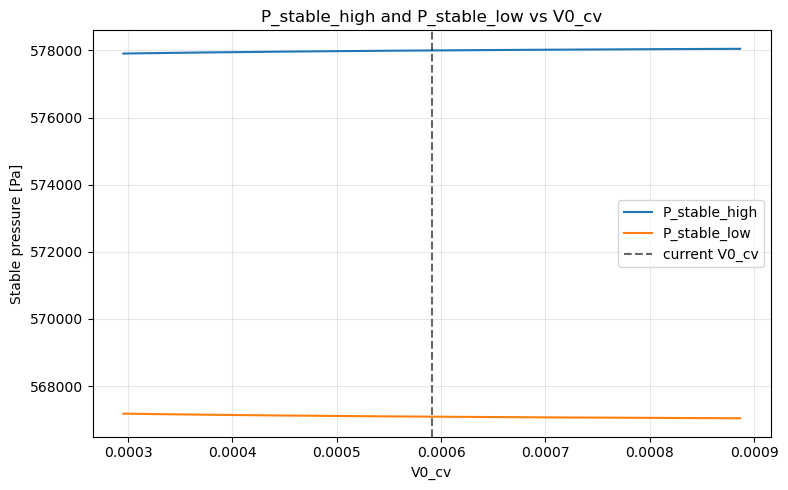

In [72]:
plt.figure(figsize=(8, 5))
plt.plot(V0_cv_grid, P_stable_high_V0_cv, label="P_stable_high")
plt.plot(V0_cv_grid, P_stable_low_V0_cv, label="P_stable_low")
plt.axvline(V0_cv, color='k', linestyle='--', alpha=0.6, label="current V0_cv")
plt.xlabel("V0_cv")
plt.ylabel("Stable pressure [Pa]")
plt.title("P_stable_high and P_stable_low vs V0_cv")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [73]:
V0_pass_grid = np.linspace(0.5 * V0_pass, 1.5 * V0_pass, 300)
P_stable_high_V0_pass = np.empty_like(V0_pass_grid)
P_stable_low_V0_pass = np.empty_like(V0_pass_grid)

for i, V0_pass_val in enumerate(V0_pass_grid):
    P_stable_high_V0_pass[i], P_stable_low_V0_pass[i] = stable_pressures_for_volumes(V0_cv, V0_pass_val)


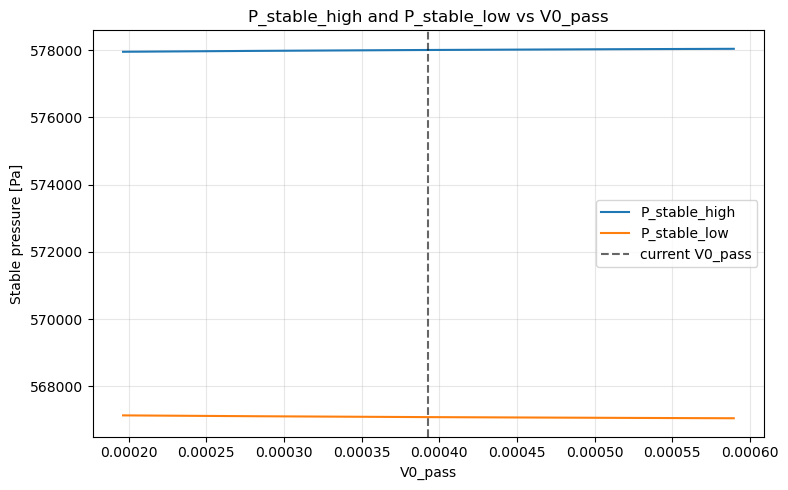

In [74]:
plt.figure(figsize=(8, 5))
plt.plot(V0_pass_grid, P_stable_high_V0_pass, label="P_stable_high")
plt.plot(V0_pass_grid, P_stable_low_V0_pass, label="P_stable_low")
plt.axvline(V0_pass, color='k', linestyle='--', alpha=0.6, label="current V0_pass")
plt.xlabel("V0_pass")
plt.ylabel("Stable pressure [Pa]")
plt.title("P_stable_high and P_stable_low vs V0_pass")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [20]:
A_neck

0.000285

In [22]:
zero_crossings_beta

[np.float64(-0.0010556833220536008), np.float64(0.0010556833220536008)]